# Diagnóstico de cancro da mama — Passive Learning (baseline)

**Inteligência Artificial Centrada no Humano** · Mestrado em Inteligência Artificial e Engenharia de Dados · FCTUC

Treina dois modelos com **todo** o conjunto de treino anotado: a CNN do grupo de 2024 (corrigida) e uma MobileNetV2 pré-treinada (*transfer learning*). Os resultados servem de referência para o Active Learning (`02_active_learning.ipynb`), que usa muito menos imagens anotadas.

> **Estado**
> - ✅ Feito: CNN corrigida e MobileNetV2, cada uma treinada com 3 seeds; métricas no teste e matrizes de confusão.
> - ⬜ Falta: Grad-CAM (#4).

**Índice**
1. Configuração
2. Dados
3. Modelos
4. Treino
5. Avaliação
6. Conclusões

## 1. Configuração

A primeira célula prepara o ambiente local:
- junta a raiz do repositório ao `sys.path`, para se poder importar o código partilhado da pasta `src/` (o notebook deve ser aberto a partir da pasta `notebooks/`, com o kernel do `.venv`);
- lê os caminhos do dataset e da pasta de resultados de `src/config.py`;
- prepara a **GPU** com `setup_gpu()` (em `src/gpu.py`) e mostra se o treino vai correr na GPU ou no CPU.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent   # raiz do repositório (o notebook está em notebooks/)
sys.path.insert(0, str(ROOT))

from src.config import DATA_PATH, RESULTS_PATH
from src.gpu import setup_gpu

setup_gpu()

A treinar na GPU: NVIDIA GeForce RTX 3050 Laptop GPU


True

### Parâmetros
- **`IMG_SIZE`**: as imagens são redimensionadas para 128×128. Também testámos 224×224 com a MobileNetV2 e não melhorou (ver a tabela da secção 3), e gasta 3× mais memória.
- **`LEARNING_RATE`**: tamanho dos passos que o otimizador dá ao ajustar os pesos.
- **`MAX_EPOCHS`** e **`PATIENCE`**: o treino pára sozinho (*early stopping*) quando a loss de validação não melhora durante `PATIENCE` épocas seguidas, até um máximo de `MAX_EPOCHS`.
- **`SEEDS`**: cada modelo é treinado 3 vezes, com inicializações aleatórias diferentes. Com um teste de só 156 imagens, uma única corrida pode ter sorte ou azar; a média e o desvio padrão são mais fiáveis.

In [2]:
# Parâmetros
IMG_SIZE = 128
LEARNING_RATE = 0.001
MAX_EPOCHS = 60
PATIENCE = 10
SEEDS = [1, 2, 3]

## 2. Dados

`load_dataset` (em `src/data.py`) faz cinco passos:

1. **Ler** as imagens em escala de cinzento e redimensionar para `IMG_SIZE × IMG_SIZE`. Os valores dos píxeis passam de 0–255 para 0–1 (normalização), o que ajuda o treino a convergir.
2. **Tirar a classe do nome do ficheiro** (ex.: `benign (12).png` → `benign`). As labels numéricas são `0 = normal`, `1 = benign`, `2 = malignant`. As imagens duplicadas são excluídas: o dataset tem a mesma imagem como `benign (433)` e `malignant (145)`, e não se sabe qual das labels está certa. Ficam 778 imagens.
3. **Dividir em três conjuntos**, de forma estratificada (cada um fica com as mesmas proporções de classes):
   - **treino (65%)**: as imagens com que o modelo aprende;
   - **validação (15%)**: para acompanhar o treino e escolher parâmetros (quando parar o treino, regularização…);
   - **teste (20%)**: só para a avaliação final.
4. **Balancear só o treino** com rotações de 90º e reflexões, até cada classe ter um número parecido de imagens. A validação e o teste ficam com as imagens originais, para medir o desempenho em condições reais.
5. **Baralhar o treino**, para as classes ficarem misturadas.

> **Porque é que a divisão vem antes do balanceamento?** Se fosse ao contrário, uma imagem podia ir para o treino e a sua versão rodada para a validação ou o teste. O modelo seria avaliado com imagens que, na prática, já viu — isto chama-se *data leakage* e dá resultados otimistas e falsos. Foi o que aconteceu no trabalho do grupo de 2024 (balancearam o dataset todo e só depois dividiram), por isso os nossos números não são diretamente comparáveis com os deles. Aqui, **nenhuma imagem de validação ou de teste, nem uma cópia dela, é usada no treino.**

In [3]:
# Carregar, dividir em treino/validação/teste e balancear só o treino
import numpy as np
from src.data import CLASSES, load_dataset, summarize

x_train, x_val, x_test, y_train, y_val, y_test = load_dataset(DATA_PATH, size=IMG_SIZE)
summarize(x_train, x_val, x_test, y_train, y_val, y_test)

Treino: (1626, 128, 128), validação: (117, 128, 128), teste: (156, 128, 128)
Memória das imagens: 124 MB
Treino: {'normal': 516, 'benign': 566, 'malignant': 544}
Validação: {'normal': 20, 'benign': 66, 'malignant': 31}
Teste: {'normal': 27, 'benign': 87, 'malignant': 42}


## 3. Modelos

### O que é uma CNN?
Uma **Rede Neuronal Convolucional** aprende sozinha que padrões da imagem (contornos, texturas, formas) ajudam a distinguir as classes. As primeiras camadas detetam padrões simples, como arestas; as seguintes combinam-nos em padrões mais complexos, como a forma de uma lesão.

### Modelo 1 — CNN treinada de raiz (`build_cnn` em `src/model.py`)
É a arquitetura do grupo de 2024:
- **4 blocos convolucionais** com 32 → 64 → 128 → 32 filtros de 4×4. Cada bloco tem:
  - `Conv2D` + ReLU: aplica os filtros e deteta padrões;
  - `BatchNormalization`: normaliza as ativações, o que estabiliza o treino;
  - `MaxPooling2D`: reduz a imagem para metade, guardando só os valores mais fortes;
  - `Dropout(0.3)` nos blocos 2 e 3: desliga 30% dos neurónios ao acaso em cada passo, para o modelo não decorar o treino (*overfitting*).
- **`Flatten` + `Dense(32)`**: junta tudo num vetor e combina os padrões encontrados.
- **`Dense(3, softmax)`**: devolve 3 probabilidades que somam 1, uma por classe. A classe prevista é a de maior probabilidade.

**O que corrigimos.** Com as definições originais (learning rate 0.00001, 15 épocas), o modelo quase não aprendia: a accuracy de validação ficou em 17% (dizia "normal" a tudo) durante 8 épocas e o teste acabou em 36%, pior do que dizer sempre "benigno" (56%). Isto é *underfitting*. Mudámos:
1. **learning rate 0.00001 → 0.001**: passos 100× maiores, o modelo aprende em poucas épocas;
2. **early stopping** em vez de um nº fixo de épocas: treina enquanto a validação melhorar e guarda a melhor época;
3. **ReLU em vez de sigmoid** na camada `Dense(32)` (a sigmoid satura e atrasa a aprendizagem) e mais um `Dropout` antes da saída.

### Modelo 2 — MobileNetV2 pré-treinada (*transfer learning*, `build_mobilenet`)
Temos só ~500 ecografias de treino originais: é pouco para uma CNN aprender de raiz o que é um contorno ou uma textura. A **MobileNetV2** já foi treinada com 1,4 milhões de imagens do ImageNet e já sabe detetar esses padrões genéricos. Reaproveitamo-la em duas fases:
1. **Rede congelada**: os pesos da MobileNetV2 não mudam; só se treina uma nova camada de saída com as nossas 3 classes.
2. ***Fine-tuning***: descongelam-se as últimas 30 camadas e continua-se a treinar com um learning rate 10× menor, para as adaptar às ecografias sem estragar o que já sabiam.

A MobileNetV2 espera imagens a cores (3 canais) com valores entre −1 e 1: a imagem em escala de cinzento é repetida 3 vezes e reescalada. Escolhemo-la porque é pequena (3,5 M parâmetros) e cabe na GPU de 4 GB.

### Experiências preliminares (fora do notebook, seed 1, accuracy no teste)
Para chegar a estas escolhas testámos várias configurações:

| Configuração | Accuracy | Recall maligno |
|---|---|---|
| CNN original (lr 0.00001, 15 épocas) | 0.36 | 0.55 |
| CNN, lr 0.0001 + early stopping | 0.17 | 0.00 |
| **CNN, lr 0.001 + early stopping** | **0.76** | 0.67 |
| CNN, lr 0.001 + pesos por classe (maligno ×1.5) | 0.75 | 0.62 |
| **MobileNetV2 128×128 + fine-tuning** | **0.85** | **0.86** |
| MobileNetV2 128×128, pesos por classe | 0.87 | 0.83 |
| MobileNetV2 só congelada, sem fine-tuning (3 seeds) | 0.77 | 0.65 |
| MobileNetV2, fine-tuning com lr 0.00001 (3 seeds) | 0.79 | 0.78 |
| MobileNetV2 224×224 | 0.78 | 0.79 |
| EfficientNetB0 128×128 | 0.78 | 0.71 |

Os **pesos por classe** (dar mais importância a errar um maligno) não ajudaram de forma consistente noutras seeds, provavelmente porque o treino já está balanceado com as rotações; por isso não os usamos.

## 4. Treino

Cada modelo é treinado com cada seed. `fit` (em `src/model.py`) treina com early stopping, usando **só** o conjunto de validação para decidir quando parar. Depois de cada treino guardam-se as previsões no teste e a memória da GPU é libertada.

São 2 modelos × 3 seeds = 6 treinos de ~1–2 minutos cada na GPU.

In [4]:
import gc
import time

from tensorflow import keras
from tensorflow.keras.utils import to_categorical
from src.evaluation import compute_metrics
from src.model import build_cnn, build_mobilenet, fit, unfreeze_top

y_train_one_hot = to_categorical(y_train, num_classes=len(CLASSES))
y_val_one_hot = to_categorical(y_val, num_classes=len(CLASSES))
data = (x_train, y_train_one_hot, x_val, y_val_one_hot)

runs = {"cnn": [], "mobilenet": []}   # runs[modelo] = lista com o resultado de cada seed
for seed in SEEDS:
    for name in runs:
        keras.utils.set_random_seed(seed)   # mesma seed = mesma inicialização e mesma ordem dos batches
        start = time.time()
        if name == "cnn":
            model = build_cnn(size=IMG_SIZE, learning_rate=LEARNING_RATE)
            histories = [fit(model, *data, max_epochs=MAX_EPOCHS, patience=PATIENCE)]
        else:
            model = build_mobilenet(size=IMG_SIZE, learning_rate=LEARNING_RATE)
            histories = [fit(model, *data, max_epochs=MAX_EPOCHS, patience=PATIENCE)]             # fase 1: congelada
            unfreeze_top(model, n_layers=30, learning_rate=LEARNING_RATE / 10)
            histories.append(fit(model, *data, max_epochs=MAX_EPOCHS, patience=PATIENCE))       # fase 2: fine-tuning

        y_pred = np.argmax(model.predict(x_test, verbose=0), axis=1)
        runs[name].append({
            "seed": seed,
            "epochs": [len(h.history["loss"]) for h in histories],
            "seconds": round(time.time() - start),
            "history": {k: [float(v) for h in histories for v in h.history[k]] for k in histories[0].history},
            "y_pred": y_pred.tolist(),
            "metrics": compute_metrics(y_test, y_pred),
        })
        r = runs[name][-1]
        print(f"{name:10s} seed {seed}: {r['seconds']:4d} s, épocas {r['epochs']}, accuracy {r['metrics']['accuracy']:.3f}, "
              f"recall maligno {r['metrics']['recall_malignant']:.3f}")
        del model
        keras.backend.clear_session()
        gc.collect()

cnn        seed 1:  121 s, épocas [33], accuracy 0.750, recall maligno 0.643


mobilenet  seed 1:  112 s, épocas [29, 21], accuracy 0.840, recall maligno 0.857


cnn        seed 2:  106 s, épocas [29], accuracy 0.705, recall maligno 0.690


mobilenet  seed 2:  119 s, épocas [30, 24], accuracy 0.846, recall maligno 0.738


cnn        seed 3:  109 s, épocas [30], accuracy 0.782, recall maligno 0.762


mobilenet  seed 3:  108 s, épocas [34, 17], accuracy 0.833, recall maligno 0.810


### Curvas de treino (seed 1)
Accuracy e loss em cada época, no treino e na validação. O que procurar:
- as duas curvas a melhorar juntas: o modelo está a aprender padrões que generalizam;
- o treino a melhorar e a validação parada ou a piorar: *overfitting* (o modelo está a decorar o treino). O early stopping pára o treino pouco depois disto começar;
- as duas curvas quase paradas: *underfitting* (era o problema da CNN original).

Na MobileNetV2, a linha vertical marca o início do fine-tuning. Nesse momento há um salto: ao descongelar camadas, os pesos começam a mudar e o modelo piora por umas épocas antes de recuperar no treino. A loss de validação sobe durante o fine-tuning, mas a accuracy no teste é melhor do que sem fine-tuning (0.84 contra 0.77, ver a tabela da secção 3). A validação tem só 117 imagens, por isso as suas curvas são ruidosas e não contam a história toda.

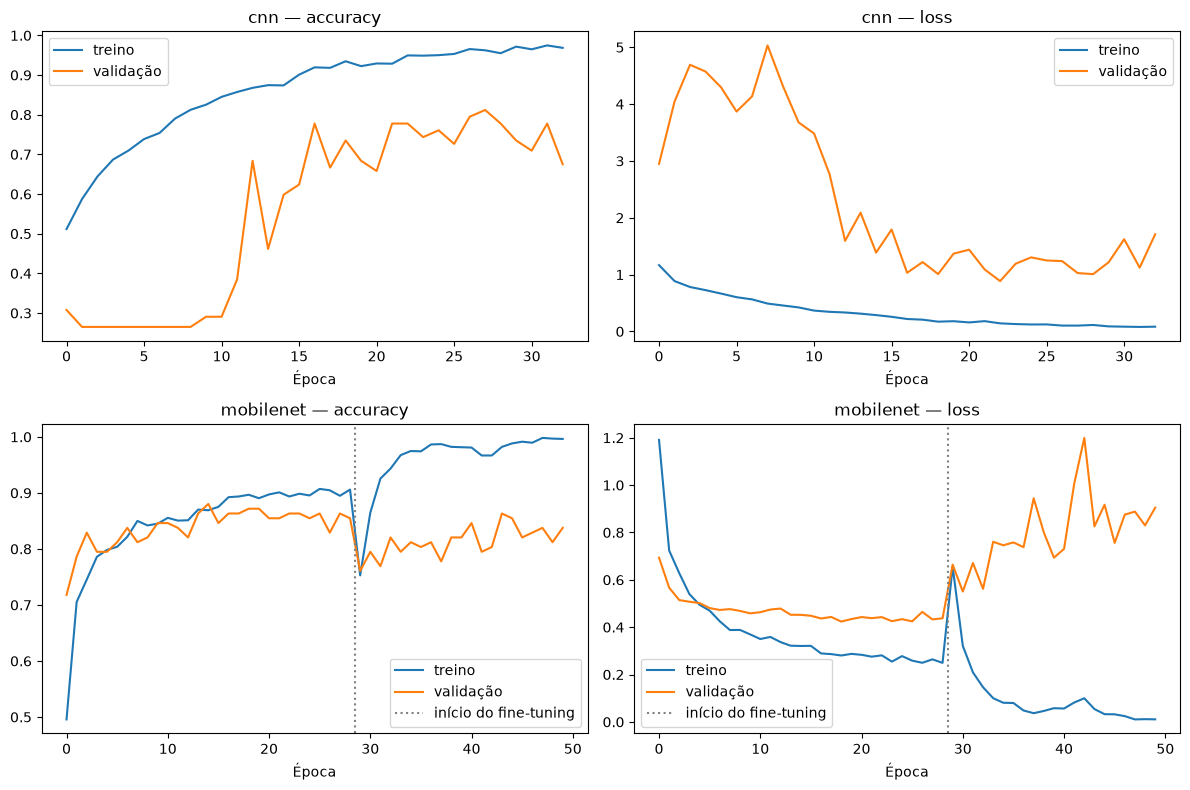

In [5]:
import matplotlib.pyplot as plt

fig, axs = plt.subplots(2, 2, figsize=(12, 8))
for row, name in zip(axs, runs):
    run = runs[name][0]
    for ax, metric in zip(row, ["accuracy", "loss"]):
        ax.plot(run["history"][metric], label="treino")
        ax.plot(run["history"][f"val_{metric}"], label="validação")
        if len(run["epochs"]) > 1:
            ax.axvline(run["epochs"][0] - 0.5, color="gray", linestyle="dotted", label="início do fine-tuning")
        ax.set_xlabel("Época")
        ax.set_title(f"{name} — {metric}")
        ax.legend()
plt.tight_layout()
plt.show()

## 5. Avaliação

Os modelos são avaliados no **conjunto de teste**, que nunca viram durante o treino.

| Métrica | O que mede |
|---|---|
| **Accuracy** | % de imagens bem classificadas. Pode enganar quando as classes não estão equilibradas. |
| **Recall** (por classe) | Dos casos que são mesmo dessa classe, quantos o modelo apanhou. `recall_macro` é a média das 3 classes. |
| **F1** | Equilíbrio entre recall e precisão (dos casos que o modelo diz serem dessa classe, quantos são mesmo). `f1_macro` é a média das 3 classes. |
| **Recall de maligno** | Dos cancros reais, quantos foram detetados. **É a métrica mais importante do projeto.** |
| **Falsos negativos (FN)** | Nº de cancros classificados como benignos ou normais. |

> **Porque é que o foco são os falsos negativos?** Num diagnóstico, um falso positivo (dizer que é maligno quando não é) leva a mais exames, o que é incómodo mas não grave. Um falso negativo (não detetar um cancro) pode atrasar o tratamento e pôr a vida em risco. Por isso preferimos um modelo com menos falsos negativos, mesmo que a accuracy seja um pouco menor.

A tabela mostra a média ± desvio padrão das 3 seeds. As métricas ficam guardadas em `results/passive_learning.json`.

In [6]:
from src.evaluation import save_json

summary = {}
for name, model_runs in runs.items():
    values = {k: np.array([r["metrics"][k] for r in model_runs]) for k in model_runs[0]["metrics"]}
    summary[name] = {"mean": {k: float(v.mean()) for k, v in values.items()},
                     "std": {k: float(v.std()) for k, v in values.items()}, "runs": model_runs}

print(f"{'modelo':<11}{'accuracy':>15}{'recall':>15}{'F1':>15}{'recall mal.':>15}{'FN':>12}")
for name, s in summary.items():
    cells = [f"{s['mean'][k]:.3f} ± {s['std'][k]:.3f}" for k in ["accuracy", "recall_macro", "f1_macro", "recall_malignant"]]
    print(f"{name:<11}" + "".join(f"{c:>15}" for c in cells) + f"{s['mean']['false_negatives']:>7.1f} ± {s['std']['false_negatives']:.1f}")

save_json(summary, RESULTS_PATH / "passive_learning.json")

modelo            accuracy         recall             F1    recall mal.          FN
cnn          0.746 ± 0.032  0.762 ± 0.013  0.728 ± 0.029  0.698 ± 0.049   12.7 ± 2.1
mobilenet    0.840 ± 0.005  0.825 ± 0.011  0.831 ± 0.008  0.802 ± 0.049    8.3 ± 2.1


### Como ler a matriz de confusão
- Cada **linha** é a classe real e cada **coluna** é a classe prevista.
- A **diagonal** são os acertos.
- Os **falsos negativos** estão na linha `malignant`, nas colunas `normal` e `benign`.

Matrizes da seed 1 de cada modelo:

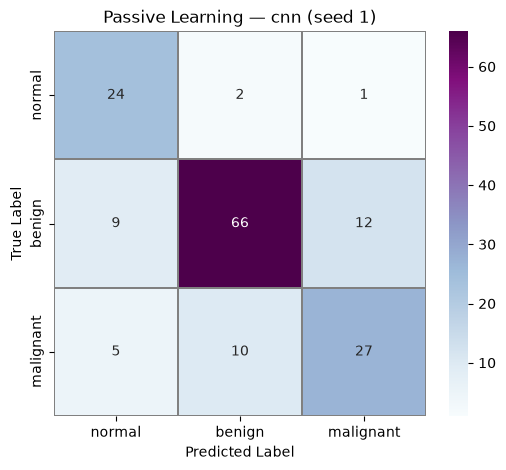

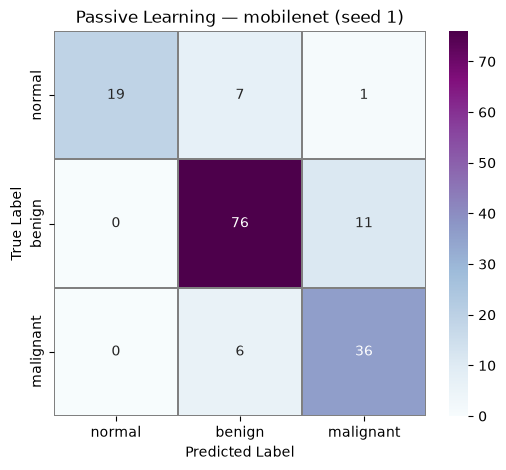

In [7]:
from src.evaluation import plot_confusion_matrix

for name in runs:
    plot_confusion_matrix(y_test, runs[name][0]["y_pred"], title=f"Passive Learning — {name} (seed 1)")

## 6. Conclusões

**Resultados no teste (média ± desvio padrão de 3 seeds, 156 imagens, 42 malignas):**

| Modelo | Accuracy | F1 macro | Recall maligno | Falsos negativos |
|---|---|---|---|---|
| CNN original (lr 0.00001, 15 épocas, 1 corrida) | 0.36 | 0.37 | 0.55 | 19 |
| CNN corrigida | 0.746 ± 0.032 | 0.728 ± 0.029 | 0.698 ± 0.049 | 12.7 ± 2.1 |
| **MobileNetV2 + fine-tuning** | **0.840 ± 0.005** | **0.831 ± 0.008** | **0.802 ± 0.049** | **8.3 ± 2.1** |

1. **A CNN do grupo de 2024 estava em *underfitting*.** Só mudar o learning rate (0.00001 → 0.001) e treinar até a validação deixar de melhorar faz a accuracy passar de 0.36 para 0.75. O grupo de 2024 tinha 45.9% de accuracy em Passive Learning com o mesmo modelo, e esse número ainda era otimista por causa do data leakage.
2. **O transfer learning é a maior melhoria:** a MobileNetV2 pré-treinada chega a 0.84 de accuracy e deteta 80% dos cancros, e varia muito menos entre seeds do que a CNN (desvio padrão 0.005 contra 0.032). Com ~500 imagens originais, aproveitar o que uma rede já aprendeu com milhões de imagens funciona melhor do que aprender tudo de raiz.
3. **A CNN faz overfitting:** a accuracy de treino chega a ~97% e a de validação fica em ~75%. O early stopping evita que piore, mas o modelo decora parte do treino.
4. **Ainda há falsos negativos:** mesmo o melhor modelo falha, em média, 8 dos 42 cancros do teste. Não chega para decidir sozinho, e é por isso que o humano tem de continuar no ciclo, com a explicabilidade (Grad-CAM, #4) a ajudá-lo a perceber em que se baseia o modelo.
5. **Cuidado com a validação pequena:** com 117 imagens, a accuracy de validação é ruidosa. A MobileNetV2 sem fine-tuning tinha melhor validação (0.87) mas pior teste (0.77). Por isso repetimos com várias seeds e não escolhemos configurações pelo teste.